In [7]:
import numpy as np
import pandas as pd

df = pd.read_csv("../laptop_data_cleaned.csv")

variable = "Weight"

# Calculate the median
median = df[variable].median()

# Calculate MAD
mad = np.median(np.abs(df[variable] - median))

# Define a threshold for noise detection
# adjust the numeric modifier for aggressiveness
# e.g. try 2.5 or 4.5 etc.
threshold = 3.0 * mad

# Detect noise
noise = df[np.abs(df[variable] - median) > threshold]

inliers = df.drop(noise.index)

print("Detected noise using MAD:")
print(f"Median: {median}, MAD: {mad}, Noise rows: {len(noise)}, Inliers: {len(inliers)}")
noise

Detected noise using MAD:
Median: 2.04, MAD: 0.3900000000000001, Noise rows: 66, Inliers: 1207


,Company,TypeName,Ram,Weight,Price,TouchScreen,Ips,Ppi,Cpu_brand,HDD,SSD,Gpu_brand,Os
50,Lenovo,2 in 1 Convertible,4,0.69,9.740752,1,1,224.173809,Other Intel Processor,0,0,Intel,Others
177,MSI,Gaming,32,4.40,11.912579,0,0,119.723216,Intel Core i7,1000,512,Nvidia,Windows
196,Razer,Gaming,32,3.49,12.691441,1,0,254.671349,Intel Core i7,0,1000,Nvidia,Windows
198,HP,Gaming,16,3.35,11.204675,0,1,127.335675,Intel Core i7,1000,256,Nvidia,Windows
224,Dell,Gaming,16,4.42,11.781989,0,1,127.335675,Intel Core i7,1000,256,Nvidia,Windows
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1189,Acer,Gaming,16,4.20,11.838443,0,1,127.335675,Intel Core i7,1000,256,Nvidia,Windows
1196,Asus,Gaming,16,4.30,11.648784,0,1,127.335675,Intel Core i7,1000,512,Nvidia,Windows
1207,Acer,Notebook,8,3.30,10.419692,0,0,106.113062,Intel Core i3,1000,0,Nvidia,Windows
1215,Acer,Notebook,4,3.30,10.369152,0,0,106.113062,Intel Core i3,1000,0,Nvidia,Windows


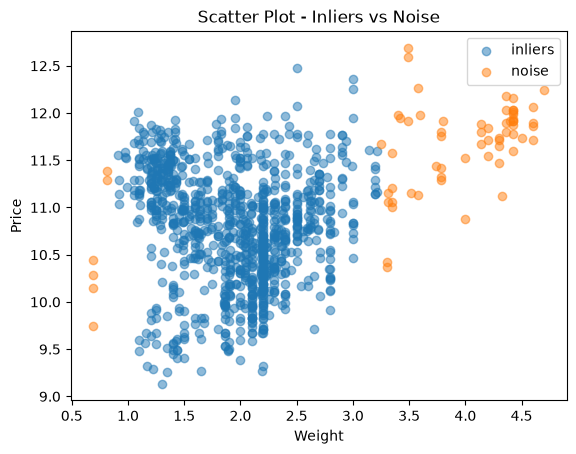

In [8]:
import matplotlib.pyplot as plt

variable = "Weight"
target = "Price"

# sample, but never more rows than exist (your dataset is small)
inliers_sample = inliers.sample(min(1000, len(inliers)), random_state=42)
outliers_sample = noise.sample(min(100, len(noise)), random_state=42)

plt.scatter(inliers_sample[variable], inliers_sample[target], label="inliers", alpha=0.5)
plt.scatter(outliers_sample[variable], outliers_sample[target], label="noise", alpha=0.5)

plt.xlabel(variable)
plt.ylabel(target)

plt.title("Scatter Plot - Inliers vs Noise")
plt.legend()
plt.show()



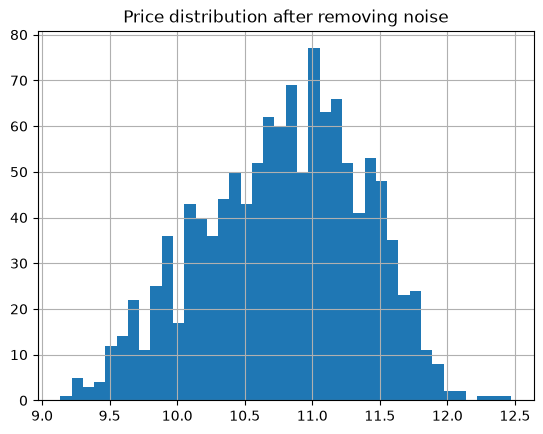

In [9]:
inliers["Price"].hist(bins=40)
plt.title("Price distribution after removing noise")
plt.show()